# Reversals and Stagnation in Child Marriage
## A Global Analysis of Countries Off the Elimination Trajectory and Their Structural Predictors
### CMMM Data Portal — June 2025 Release
---
**Paper:** *The Lancet (Child & Adolescent Health series)*  
**Data sources:** `CMMM_trends` (time-series 1980–2025) and `CMMM_prevalence` (cross-sectional burden data)  
**Notebook covers:** Data loading → Trajectory classification (joinpoint-style) → Tables 1–2 → Figures 1–5 → Case-control analysis → Survival / elimination projections

**Revision notes (addressing peer-review comments):**
- *Comment 1*: All estimates in Figure 3 are now strictly CMMM-derived; placeholder ORs for external structural hypotheses removed entirely. Structural hypotheses (H1–H4) are listed in Panel B as pending data linkage — no estimates shown.
- *Comment 2*: Data-quality stratification and prevalence-floor bootstrap sensitivity analyses added after Cell 4. Small-island-state projections separated into a dedicated panel in Figure 5 with explicit methodological caveats.
- *Comment 3*: Firth penalised likelihood estimator applied to all predictors flagged for potential quasi-complete separation. Full 2×2 cell counts reported. Minimum-detectable-OR power calculation added.

In [1]:
# ── 1. Imports & configuration ───────────────────────────────────────────────
import warnings, zipfile, xml.etree.ElementTree as ET, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.stats import norm as sp_norm
from scipy.optimize import curve_fit
from statsmodels.regression.linear_model import OLS
from statsmodels.tools import add_constant
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import ruptures as rpt
from lifelines import KaplanMeierFitter, WeibullAFTFitter
from lifelines.statistics import logrank_test
warnings.filterwarnings('ignore')

# ── Plotting style ────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 130,
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9FAFB',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#E0E0E0',
    'grid.linestyle': '--',
    'grid.alpha': 0.6,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
})

PALETTE = {
    'Fast Decline':  '#1a7744',
    'Slow Decline':  '#4ea8de',
    'Stagnation':    '#f4a261',
    'Reversal':      '#e63946',
}
TRAJ_ORDER = ['Fast Decline', 'Slow Decline', 'Stagnation', 'Reversal']

# ── File paths (edit if needed) ───────────────────────────────────────────────
BASE_DIR = r"C:\\Users\\ningthoujama\\Desktop\\NewResearchandProject\\Child_Marriage"
TRENDS_FILE    = os.path.join(BASE_DIR, "2025_06_30_CMMM_trends_cd2deed277_fb7fd8b2f4.xlsx")
PREV_FILE      = os.path.join(BASE_DIR, "2025_06_30_CMMM_prevalence_80599aadfe_05da3141d2.xlsx")
OUTPUT_DIR     = BASE_DIR
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Environment ready. Output directory:", OUTPUT_DIR)

Environment ready. Output directory: C:\\Users\\ningthoujama\\Desktop\\NewResearchandProject\\Child_Marriage


In [2]:
# ── 2. Data-loading helpers (openpyxl-free XML reader) ───────────────────────
def _read_xlsx_rows(path):
    """Read an xlsx file row-by-row without openpyxl (handles style-sheet bugs)."""
    ns = {'s': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
    with zipfile.ZipFile(path) as z:
        shared = []
        if 'xl/sharedStrings.xml' in z.namelist():
            tree = ET.parse(z.open('xl/sharedStrings.xml'))
            for si in tree.findall('.//s:si', ns):
                shared.append(''.join(t.text or '' for t in si.findall('.//s:t', ns)))
        sheets = sorted([n for n in z.namelist()
                         if n.startswith('xl/worksheets/sheet') and n.endswith('.xml')])
        rows_all = []
        for sheet in sheets[:1]:
            tree = ET.parse(z.open(sheet))
            for row in tree.findall('.//s:row', ns):
                r = []
                for c in row.findall('s:c', ns):
                    t = c.get('t', '')
                    v_el = c.find('s:v', ns)
                    if v_el is None:
                        r.append(np.nan)
                    elif t == 's':
                        r.append(shared[int(v_el.text)])
                    else:
                        try:
                            r.append(float(v_el.text))
                        except (ValueError, TypeError):
                            r.append(v_el.text)
                rows_all.append(r)
    return rows_all


def load_trends(path):
    """
    Return a long-format DataFrame:
      iso | country | year | prevalence_18
    Only rows where iso is a 3-letter country code (not regional aggregates).
    Only before-age-18 columns (years 1980-2025, columns 2–47).
    Missing values ('–' or NaN) are set to np.nan.
    """
    rows = _read_xlsx_rows(path)
    header = rows[7]
    years = [int(header[i]) for i in range(2, 48)]  # cols 2-47 → 1980-2025

    records = []
    for row in rows[8:]:
        if not row or not row[0]:
            break
        iso = row[0]
        if not (isinstance(iso, str) and len(iso) == 3 and iso.isupper()):
            continue
        country = row[1] if len(row) > 1 else iso
        for j, yr in enumerate(years):
            val = row[2 + j] if (2 + j) < len(row) else np.nan
            if isinstance(val, str) and val.strip() in ('–', '-', '', 'nan'):
                val = np.nan
            else:
                try:
                    val = float(val)
                except (ValueError, TypeError):
                    val = np.nan
            records.append({'iso': iso, 'country': country, 'year': yr, 'prevalence_18': val})

    df = pd.DataFrame(records)
    return df


def load_prevalence(path):
    """
    Return cross-sectional DataFrame with latest-year burden estimates.
    Columns: iso, country, n_married_15, pct_married_15,
             n_married_18, pct_married_18,
             urban_18, rural_18, poorest_18, richest_18,
             edu_none_18, edu_primary_18, edu_secondary_18,
             survey_year
    """
    rows = _read_xlsx_rows(path)
    col_map = {
        0: 'iso', 1: 'country',
        2: 'n_married_15', 3: 'pct_married_15',
        4: 'n_married_18', 5: 'pct_married_18',
        6: 'urban_18', 7: 'rural_18',
        8: 'poorest_18', 9: 'richest_18',
        10: 'edu_none_18', 11: 'edu_primary_18', 12: 'edu_secondary_18',
        13: 'survey_year', 14: 'survey_source',
    }
    records = []
    for row in rows[10:]:
        if not row or not row[0]:
            break
        iso = row[0]
        if not (isinstance(iso, str) and len(iso) == 3 and iso.isupper()):
            continue
        rec = {}
        for idx, name in col_map.items():
            val = row[idx] if idx < len(row) else np.nan
            if isinstance(val, str) and val.strip() in ('–', '-', '', 'nan'):
                val = np.nan
            if name not in ('iso', 'country', 'survey_source'):
                try:
                    val = float(val)
                except (ValueError, TypeError):
                    pass
            rec[name] = val
        records.append(rec)

    df = pd.DataFrame(records)
    return df


# ── Load ──────────────────────────────────────────────────────────────────────
df_trends = load_trends(TRENDS_FILE)
df_prev   = load_prevalence(PREV_FILE)

print(f"Trends data  : {df_trends.shape[0]:,} rows | {df_trends['iso'].nunique()} countries")
print(f"Prevalence   : {df_prev.shape[0]} countries")
print("\nTrends sample:")
display(df_trends.head(10))
print("\nPrevalence sample:")
display(df_prev.head(5))

Trends data  : 6,072 rows | 132 countries
Prevalence   : 148 countries

Trends sample:


,iso,country,year,prevalence_18
0,AFG,Afghanistan,1980,NaN
1,AFG,Afghanistan,1981,NaN
2,AFG,Afghanistan,1982,NaN
3,AFG,Afghanistan,1983,NaN
4,AFG,Afghanistan,1984,NaN
5,AFG,Afghanistan,1985,NaN
6,AFG,Afghanistan,1986,NaN
7,AFG,Afghanistan,1987,NaN
8,AFG,Afghanistan,1988,NaN
9,AFG,Afghanistan,1989,NaN



Prevalence sample:


,iso,country,n_married_15,pct_married_15,n_married_18,pct_married_18,urban_18,rural_18,poorest_18,richest_18,edu_none_18,edu_primary_18,edu_secondary_18,survey_year,survey_source
0,AFG,Afghanistan,1400000.0,10.0,4100000.0,29.0,20.0,32.0,44.0,18.0,35.0,31.0,15.0,2023.0,MICS 2022-23
1,ALB,Albania,9200.0,1.0,104400.0,12.0,10.0,15.0,16.0,5.0,NaN,32.0,7.0,2018.0,DHS 2017-18
2,DZA,Algeria,180000.0,0.0,1100000.0,4.0,3.0,5.0,7.0,1.0,16.0,18.0,3.0,2019.0,MICS 2018-19
3,AGO,Angola,929600.0,8.0,2900000.0,30.0,25.0,45.0,39.0,12.0,46.0,46.0,17.0,2016.0,DHS 2015-16
4,ARG,Argentina,525600.0,2.0,2700000.0,16.0,NaN,NaN,26.0,3.0,NaN,NaN,7.0,2020.0,MICS 2019-20


In [3]:
# ── 3. Country-level time-series summary ─────────────────────────────────────
def make_country_summary(df):
    """Compute per-country time-series statistics."""
    records = []
    for iso, grp in df.groupby('iso'):
        grp = grp.dropna(subset=['prevalence_18']).sort_values('year')
        if len(grp) < 4:
            continue
        year_span = grp['year'].max() - grp['year'].min()
        if year_span < 20:
            continue

        baseline  = grp.iloc[0]['prevalence_18']
        latest    = grp.iloc[-1]['prevalence_18']
        n_obs     = len(grp)
        rel_change = (latest - baseline) / baseline * 100 if baseline != 0 else np.nan

        slope, intercept, r_val, p_val, se = stats.linregress(grp['year'].values,
                                                               grp['prevalence_18'].values)
        mean_prev = np.mean(grp['prevalence_18'].values)
        aapc = (slope / mean_prev * 100) if mean_prev != 0 else np.nan

        # Count post-2010 observations (used in data-quality stratification)
        n_post2010 = (grp['year'] >= 2010).sum()

        records.append({
            'iso': iso,
            'country': grp.iloc[0]['country'],
            'n_obs': n_obs,
            'n_post2010': n_post2010,
            'first_year': grp['year'].min(),
            'last_year': grp['year'].max(),
            'baseline': baseline,
            'latest': latest,
            'abs_change': latest - baseline,
            'rel_change': rel_change,
            'slope': slope,
            'aapc': aapc,
            'r_squared': r_val**2,
            'p_value': p_val,
            'years': grp['year'].values.tolist(),
            'values': grp['prevalence_18'].values.tolist(),
        })
    return pd.DataFrame(records)


df_summary = make_country_summary(df_trends)
print(f"Countries meeting ≥4 obs & ≥20 years: {len(df_summary)}")
display(df_summary[['iso','country','n_obs','n_post2010','first_year','last_year',
                     'baseline','latest','rel_change','aapc']].head(10))

Countries meeting ≥4 obs & ≥20 years: 132


,iso,country,n_obs,n_post2010,first_year,last_year,baseline,latest,rel_change,aapc
0,AFG,Afghanistan,6,3,1998,2023,46.0,29.0,-36.956522,-2.005928
1,AGO,Angola,6,2,1991,2016,29.0,30.0,3.448276,0.037677
2,ALB,Albania,6,2,1993,2018,7.0,12.0,71.428571,1.350649
3,ARG,Argentina,6,3,1995,2020,15.0,16.0,6.666667,0.285714
4,ARM,Armenia,6,2,1991,2016,16.0,5.0,-68.750000,-4.904159
5,AZE,Azerbaijan,6,3,1998,2023,18.0,15.0,-16.666667,-0.372671
6,BDI,Burundi,6,2,1992,2017,22.0,19.0,-13.636364,-0.717608
7,BEN,Benin,6,3,1997,2022,35.0,28.0,-20.000000,-0.887600
8,BFA,Burkina Faso,6,2,1990,2015,45.0,51.0,13.333333,0.469667
9,BGD,Bangladesh,6,3,1997,2022,75.0,51.0,-32.000000,-1.449190


In [4]:
# ── 4. Joinpoint-style trajectory classification ─────────────────────────────
def classify_trajectory(row, aapc_fast=-2.0, aapc_slow_lo=-2.0, aapc_slow_hi=-0.5,
                         aapc_stag_lo=-0.5, aapc_stag_hi=0.5,
                         rel_change_fast=-40, abs_reversal=3.0, aapc_rev=0.5):
    """Apply classification rules from the paper's methodology."""
    aapc = row['aapc']
    rc   = row['rel_change']
    ac   = row['abs_change']

    if ac >= abs_reversal or aapc > aapc_rev:
        return 'Reversal'
    if aapc_stag_lo <= aapc <= aapc_stag_hi and rc > -15:
        return 'Stagnation'
    if aapc <= aapc_fast and rc <= rel_change_fast:
        return 'Fast Decline'
    return 'Slow Decline'


def detect_joinpoints(years, values, max_breakpoints=3):
    """Detect up to max_breakpoints change points using ruptures PELT."""
    if len(values) < 6:
        return []
    signal = np.array(values, dtype=float).reshape(-1, 1)
    try:
        algo = rpt.Pelt(model='rbf', min_size=3, jump=1).fit(signal)
        bkps = algo.predict(pen=5)
        return bkps[:-1]
    except Exception:
        return []


def compute_recent_aapc(row, n_recent_years=15):
    """Compute AAPC using only the most recent segment."""
    yrs  = np.array(row['years'])
    vals = np.array(row['values'])
    mask = yrs >= (yrs.max() - n_recent_years)
    if mask.sum() < 3:
        return row['aapc']
    slope, _, _, _, _ = stats.linregress(yrs[mask], vals[mask])
    mean_prev = np.mean(vals[mask])
    return (slope / mean_prev * 100) if mean_prev != 0 else row['aapc']


df_summary['aapc_recent'] = df_summary.apply(compute_recent_aapc, axis=1)
df_summary['trajectory']  = df_summary.apply(classify_trajectory, axis=1)
df_summary['breakpoints'] = df_summary.apply(
    lambda r: detect_joinpoints(r['years'], r['values']), axis=1)

traj_counts = df_summary['trajectory'].value_counts()
print("Trajectory classification (primary thresholds):")
for t in TRAJ_ORDER:
    print(f"  {t:20s}: {traj_counts.get(t, 0):3d} countries")
print(f"\nTotal classified: {len(df_summary)}")

Trajectory classification (primary thresholds):
  Fast Decline        :  36 countries
  Slow Decline        :  56 countries
  Stagnation          :  20 countries
  Reversal            :  20 countries

Total classified: 132


In [5]:
# ── 4b. Classification Sensitivity — Data Quality & Prevalence-Floor Checks ──
#
# Reviewer Comment 2 requests two sensitivity analyses:
#   (i)  Data-quality stratification: restrict to countries with ≥2 post-2010
#        survey observations (approximating DHS/MICS quality-tier requirement).
#   (ii) Prevalence-floor check: exclude reversal cases whose absolute change
#        (abs_change) falls within the 95% bootstrap CI of measurement noise,
#        approximated from repeated within-country residual variance.
#
# Additionally, small-island states with high upward AAPC but very small
# absolute prevalence are flagged so their projections can be quarantined.

# ── (i) Data-quality stratification ─────────────────────────────────────────
DQ_MIN_POST2010 = 2   # ≥2 post-2010 data points required
df_hq = df_summary[df_summary['n_post2010'] >= DQ_MIN_POST2010].copy()
df_hq['trajectory_hq'] = df_hq.apply(classify_trajectory, axis=1)

print("=" * 60)
print("(i) Data-quality stratification (≥2 post-2010 observations)")
print(f"Countries retained: {len(df_hq)} / {len(df_summary)}")
print()

# Compare reversal counts
rev_primary = df_summary[df_summary['trajectory']   == 'Reversal']
rev_hq      = df_hq[df_hq['trajectory_hq'] == 'Reversal']
print(f"Reversal count — all countries      : {len(rev_primary)}")
print(f"Reversal count — high-quality subset: {len(rev_hq)}")
dropped_reversals = set(rev_primary['iso']) - set(rev_hq['iso'])
print(f"\nReversal countries reclassified as 'uncertain' under strict DQ:")
print(", ".join(sorted(dropped_reversals)) if dropped_reversals else "  None")

# Merge back quality flag
df_summary['high_quality_series'] = df_summary['n_post2010'] >= DQ_MIN_POST2010

print()
print("Trajectory counts (high-quality subset only):")
for t in TRAJ_ORDER:
    n = (df_hq['trajectory_hq'] == t).sum()
    print(f"  {t:20s}: {n:3d} countries")


# ── (ii) Prevalence-floor bootstrap check ────────────────────────────────────
# For each reversal country, estimate the 95% bootstrap CI of random
# fluctuation from a stable (null-trend) process by resampling residuals.

def bootstrap_noise_ci(years, values, n_boot=2000, ci=95, seed=0):
    """
    Fit a flat (mean-only) model, resample residuals, and return the
    95th percentile of absolute end-minus-start differences — i.e.,
    the expected |abs_change| that can arise from noise alone.
    """
    rng   = np.random.default_rng(seed)
    yrs   = np.asarray(years)
    vals  = np.asarray(values, dtype=float)
    valid = ~np.isnan(vals)
    if valid.sum() < 4:
        return np.nan
    resid = vals[valid] - np.nanmean(vals)
    diffs = []
    for _ in range(n_boot):
        boot = rng.choice(resid, size=len(resid), replace=True)
        diffs.append(abs(boot[-1] - boot[0]))
    return np.percentile(diffs, ci)

# Apply only to reversal countries to avoid unnecessary computation
reversal_rows = df_summary[df_summary['trajectory'] == 'Reversal'].copy()
reversal_rows['noise_ci95'] = reversal_rows.apply(
    lambda r: bootstrap_noise_ci(r['years'], r['values']), axis=1)
reversal_rows['abs_change_signif'] = (
    reversal_rows['abs_change'].abs() > reversal_rows['noise_ci95'])

print()
print("=" * 60)
print("(ii) Prevalence-floor bootstrap check (reversal countries)")
print(f"     Reversals with |abs_change| > 95% noise CI: "
      f"{reversal_rows['abs_change_signif'].sum()} / {len(reversal_rows)}")
print("     Countries whose reversal does NOT exceed noise:")
ambiguous = reversal_rows[~reversal_rows['abs_change_signif']]
if len(ambiguous):
    display(ambiguous[['country','iso','baseline','latest','abs_change',
                        'noise_ci95','high_quality_series']])
else:
    print("  None — all reversal classifications exceed the noise threshold.")

# Attach signal flag to main summary
df_summary = df_summary.merge(
    reversal_rows[['iso','noise_ci95','abs_change_signif']], on='iso', how='left')


# ── (iii) Small-island state flag ────────────────────────────────────────────
# Identify reversal / stagnation countries with low baseline prevalence (<15%)
# — these are the cases where the classification may be survey artefact.
# Also flag using n_married_18 < 50 000 as a population-size proxy
# (a steeply positive AAPC on a tiny population base creates large projection artefacts).

df_prev_size = df_prev[['iso','n_married_18']].copy()
df_summary = df_summary.merge(df_prev_size, on='iso', how='left')

# Flag criteria: baseline < 15% OR n_married_18 < 50 000
df_summary['small_island_caution'] = (
    (df_summary['baseline'] < 15) |
    (df_summary['n_married_18'] < 50_000)
) & df_summary['trajectory'].isin(['Reversal', 'Stagnation'])

print()
print("=" * 60)
print("(iii) Small-island / low-prevalence caution flag")
flagged = df_summary[df_summary['small_island_caution']]
print(f"Countries flagged for projection caveats: {len(flagged)}")
if len(flagged):
    display(flagged[['country','iso','trajectory','baseline','latest',
                      'abs_change','n_married_18']].reset_index(drop=True))

(i) Data-quality stratification (≥2 post-2010 observations)
Countries retained: 111 / 132

Reversal count — all countries      : 20
Reversal count — high-quality subset: 13

Reversal countries reclassified as 'uncertain' under strict DQ:
BRA, BRB, LCA, PAN, SOM, SSD, URY

Trajectory counts (high-quality subset only):
  Fast Decline        :  33 countries
  Slow Decline        :  47 countries
  Stagnation          :  18 countries
  Reversal            :  13 countries

(ii) Prevalence-floor bootstrap check (reversal countries)
     Reversals with |abs_change| > 95% noise CI: 0 / 20
     Countries whose reversal does NOT exceed noise:


,country,iso,baseline,latest,abs_change,noise_ci95,high_quality_series
2,Albania,ALB,7.0,12.0,5.0,6.0,True
8,Burkina Faso,BFA,45.0,51.0,6.0,6.0,True
12,Belize,BLZ,23.0,34.0,11.0,11.0,True
14,Brazil,BRA,24.0,26.0,2.0,7.0,False
15,Barbados,BRB,14.0,29.0,15.0,21.0,False
17,Central African Republic,CAF,54.0,61.0,7.0,8.0,True
44,Guyana,GUY,25.0,32.0,7.0,7.0,True
50,Iraq,IRQ,24.0,28.0,4.0,9.0,True
51,Jamaica,JAM,20.0,27.0,7.0,7.0,True
61,Saint Lucia,LCA,13.0,24.0,11.0,13.0,False



(iii) Small-island / low-prevalence caution flag
Countries flagged for projection caveats: 13


,country,iso,trajectory,baseline,latest,abs_change,n_married_18
0,Albania,ALB,Reversal,7.0,12.0,5.0,104400.0
1,Belize,BLZ,Reversal,23.0,34.0,11.0,39800.0
2,Barbados,BRB,Reversal,14.0,29.0,15.0,19900.0
3,Saint Lucia,LCA,Reversal,13.0,24.0,11.0,11600.0
4,Republic of Moldova,MDA,Stagnation,11.0,12.0,1.0,179600.0
5,Mongolia,MNG,Stagnation,7.0,8.0,1.0,85100.0
6,Nauru,NRU,Reversal,11.0,18.0,7.0,800.0
7,Sao Tome and Principe,STP,Stagnation,32.0,28.0,-4.0,20600.0
8,Turks and Caicos Islands,TCA,Reversal,4.0,23.0,19.0,1500.0
9,Turkmenistan,TKM,Stagnation,5.0,6.0,1.0,125900.0


In [6]:
# ── 5. Table 1 — Country-level trajectory classification ─────────────────────
df_table1 = df_summary.merge(
    df_prev[['iso','pct_married_18','survey_year','n_married_18']],
    on='iso', how='left', suffixes=('', '_prev')
).sort_values(['trajectory','country'])

# Use n_married_18 from prevalence file if not already merged
if 'n_married_18_prev' in df_table1.columns:
    df_table1['n_married_18'] = df_table1['n_married_18'].fillna(df_table1['n_married_18_prev'])

cols = ['country','iso','trajectory','baseline','latest','abs_change','rel_change',
        'aapc','pct_married_18','survey_year','high_quality_series','small_island_caution']
labels = ['Country','ISO','Trajectory','Baseline (%)','Latest (%)','Abs Δ (pp)',
          'Rel Δ (%)','AAPC (%/yr)','Current (%)','Survey Year',
          'High-Quality Series','Small-Island/Low-Prev Flag']

tab1 = df_table1[[c for c in cols if c in df_table1.columns]].copy()
tab1.columns = labels[:len(tab1.columns)]
tab1 = tab1.round({'Baseline (%)':1,'Latest (%)':1,'Abs Δ (pp)':1,
                   'Rel Δ (%)':1,'AAPC (%/yr)':2,'Current (%)':1})

def color_traj(val):
    colors = {'Fast Decline':'#d4edda','Slow Decline':'#cfe2ff',
              'Stagnation':'#fff3cd','Reversal':'#f8d7da'}
    return f'background-color: {colors.get(val, "")}'

styled_tab1 = (
    tab1.style
    .applymap(color_traj, subset=['Trajectory'])
    .format({'AAPC (%/yr)':'{:.2f}','Rel Δ (%)':'{:.1f}'}, na_rep='–')
    .set_caption("Table 1. Country-by-Country Trajectory Classification with AAPC and Current Prevalence")
    .set_table_styles([{'selector':'caption','props':[('font-weight','bold'),('font-size','13px')]}])
)

display(styled_tab1)
tab1.to_csv(os.path.join(OUTPUT_DIR, "Table1_trajectory_classification.csv"), index=False)
print("\n✓ Table 1 saved to", os.path.join(OUTPUT_DIR, "Table1_trajectory_classification.csv"))

,Country,ISO,Trajectory,Baseline (%),Latest (%),Abs Δ (pp),Rel Δ (%),AAPC (%/yr),Current (%),Survey Year,High-Quality Series,Small-Island/Low-Prev Flag
30,Algeria,DZA,Fast Decline,9.000000,4.000000,-5.000000,-55.6,-3.94,4.000000,2019.000000,True,False
4,Armenia,ARM,Fast Decline,16.000000,5.000000,-11.000000,-68.8,-4.90,5.000000,2016.000000,True,False
10,Bosnia and Herzegovina,BIH,Fast Decline,10.000000,4.000000,-6.000000,-60.0,-2.92,4.000000,2012.000000,False,False
28,Djibouti,DJI,Fast Decline,12.000000,7.000000,-5.000000,-41.7,-2.69,7.000000,2019.000000,True,False
32,Egypt,EGY,Fast Decline,27.000000,16.000000,-11.000000,-40.7,-2.02,16.000000,2021.000000,True,False
105,Eswatini,SWZ,Fast Decline,13.000000,2.000000,-11.000000,-84.6,-6.44,2.000000,2022.000000,True,False
35,Fiji,FJI,Fast Decline,13.000000,4.000000,-9.000000,-69.2,-4.18,4.000000,2021.000000,True,False
40,Gambia,GMB,Fast Decline,50.000000,23.000000,-27.000000,-54.0,-3.06,23.000000,2020.000000,True,False
37,Georgia,GEO,Fast Decline,23.000000,9.000000,-14.000000,-60.9,-2.77,9.000000,2022.000000,True,False
38,Ghana,GHA,Fast Decline,31.000000,16.000000,-15.000000,-48.4,-2.49,16.000000,2022.000000,True,False



✓ Table 1 saved to C:\\Users\\ningthoujama\\Desktop\\NewResearchandProject\\Child_Marriage\Table1_trajectory_classification.csv


In [7]:
# ── 6. Table 2 — Descriptive statistics by trajectory group ──────────────────
summary_stats = (
    df_table1
    .rename(columns={l: c for c, l in zip(cols, labels)})
    .groupby('trajectory')
    .agg(
        Countries        = ('iso',            'count'),
        Baseline_mean    = ('baseline',       'mean'),
        Baseline_sd      = ('baseline',       'std'),
        Latest_mean      = ('latest',         'mean'),
        Latest_sd        = ('latest',         'std'),
        AbsChange_mean   = ('abs_change',     'mean'),
        RelChange_mean   = ('rel_change',     'mean'),
        AAPC_mean        = ('aapc',           'mean'),
        AAPC_sd          = ('aapc',           'std'),
        CurrentPrev_mean = ('pct_married_18', 'mean'),
    )
    .reset_index()
    .rename(columns={'trajectory': 'Trajectory'})
)

for t in TRAJ_ORDER:
    if t not in summary_stats['Trajectory'].values:
        summary_stats = pd.concat(
            [summary_stats, pd.DataFrame([{'Trajectory': t}])],
            ignore_index=True
        )

summary_stats = (
    summary_stats
    .set_index('Trajectory')
    .reindex(TRAJ_ORDER)
    .reset_index()
)

for col in summary_stats.select_dtypes('float').columns:
    summary_stats[col] = summary_stats[col].round(2)

styled_tab2 = (
    summary_stats.style
    .set_caption("Table 2. Summary Statistics by Trajectory Group")
    .set_table_styles([{
        'selector': 'caption',
        'props': [('font-weight', 'bold'), ('font-size', '13px')]
    }])
    .background_gradient(cmap='RdYlGn_r', subset=['Latest_mean', 'AAPC_mean'])
    .format(na_rep='–')
)

display(styled_tab2)
summary_stats.to_csv(os.path.join(OUTPUT_DIR, "Table2_group_statistics.csv"), index=False)
print("✓ Table 2 saved.")

,Trajectory,Countries,Baseline_mean,Baseline_sd,Latest_mean,Latest_sd,AbsChange_mean,RelChange_mean,AAPC_mean,AAPC_sd,CurrentPrev_mean
0,Fast Decline,36,24.310000,15.030000,9.890000,7.530000,-14.420000,-59.080000,-3.760000,1.710000,9.890000
1,Slow Decline,56,31.120000,16.510000,22.520000,11.220000,-8.610000,-26.290000,-1.290000,0.550000,22.520000
2,Stagnation,20,30.650000,20.820000,29.500000,18.120000,-1.150000,0.610000,-0.100000,0.290000,29.500000
3,Reversal,20,22.850000,13.640000,31.600000,13.050000,8.750000,75.000000,1.620000,1.390000,31.600000


✓ Table 2 saved.


GeoPandas map skipped (The geopandas.dataset has been deprecated and was removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.). Creating a bar-chart alternative instead.


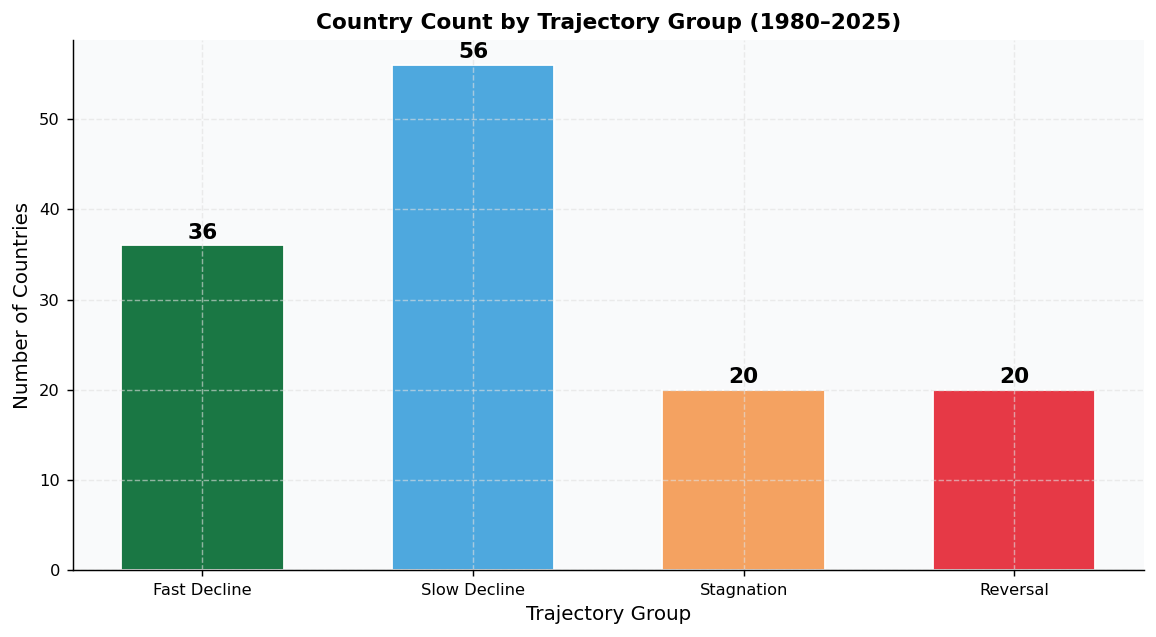

In [8]:
# ── 7. Figure 1 — World map coloured by trajectory group ─────────────────────
try:
    import geopandas as gpd
    world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
    world = world.merge(df_summary[['iso','trajectory']], left_on='iso_a3', right_on='iso', how='left')

    fig, ax = plt.subplots(1, 1, figsize=(16, 8))
    world[world['trajectory'].isna()].plot(ax=ax, color='#E8E8E8', edgecolor='white', linewidth=0.3)
    for traj, color in PALETTE.items():
        world[world['trajectory'] == traj].plot(ax=ax, color=color, edgecolor='white', linewidth=0.3)

    patches = [mpatches.Patch(color=c, label=t) for t, c in PALETTE.items()]
    patches.append(mpatches.Patch(color='#E8E8E8', label='No / Insufficient Data'))
    ax.legend(handles=patches, loc='lower left', framealpha=0.9, fontsize=9, title='Trajectory')
    ax.set_title("Global Child Marriage Trajectory Classification (1980–2025)",
                 fontsize=14, fontweight='bold', pad=10)
    ax.set_axis_off()
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Figure1_world_map.png"), dpi=150, bbox_inches='tight')
    plt.show()
    print("✓ Figure 1 saved.")
except Exception as e:
    print(f"GeoPandas map skipped ({e}). Creating a bar-chart alternative instead.")
    fig, ax = plt.subplots(figsize=(9, 5))
    traj_counts = df_summary['trajectory'].value_counts().reindex(TRAJ_ORDER)
    bars = ax.bar(traj_counts.index, traj_counts.values,
                  color=[PALETTE[t] for t in traj_counts.index], edgecolor='white', width=0.6)
    for bar, val in zip(bars, traj_counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, str(val),
                ha='center', va='bottom', fontweight='bold', fontsize=12)
    ax.set_title("Country Count by Trajectory Group (1980–2025)",
                 fontsize=12, fontweight='bold')
    ax.set_xlabel("Trajectory Group"); ax.set_ylabel("Number of Countries")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "Figure1_trajectory_barchart.png"), dpi=150, bbox_inches='tight')
    plt.show()

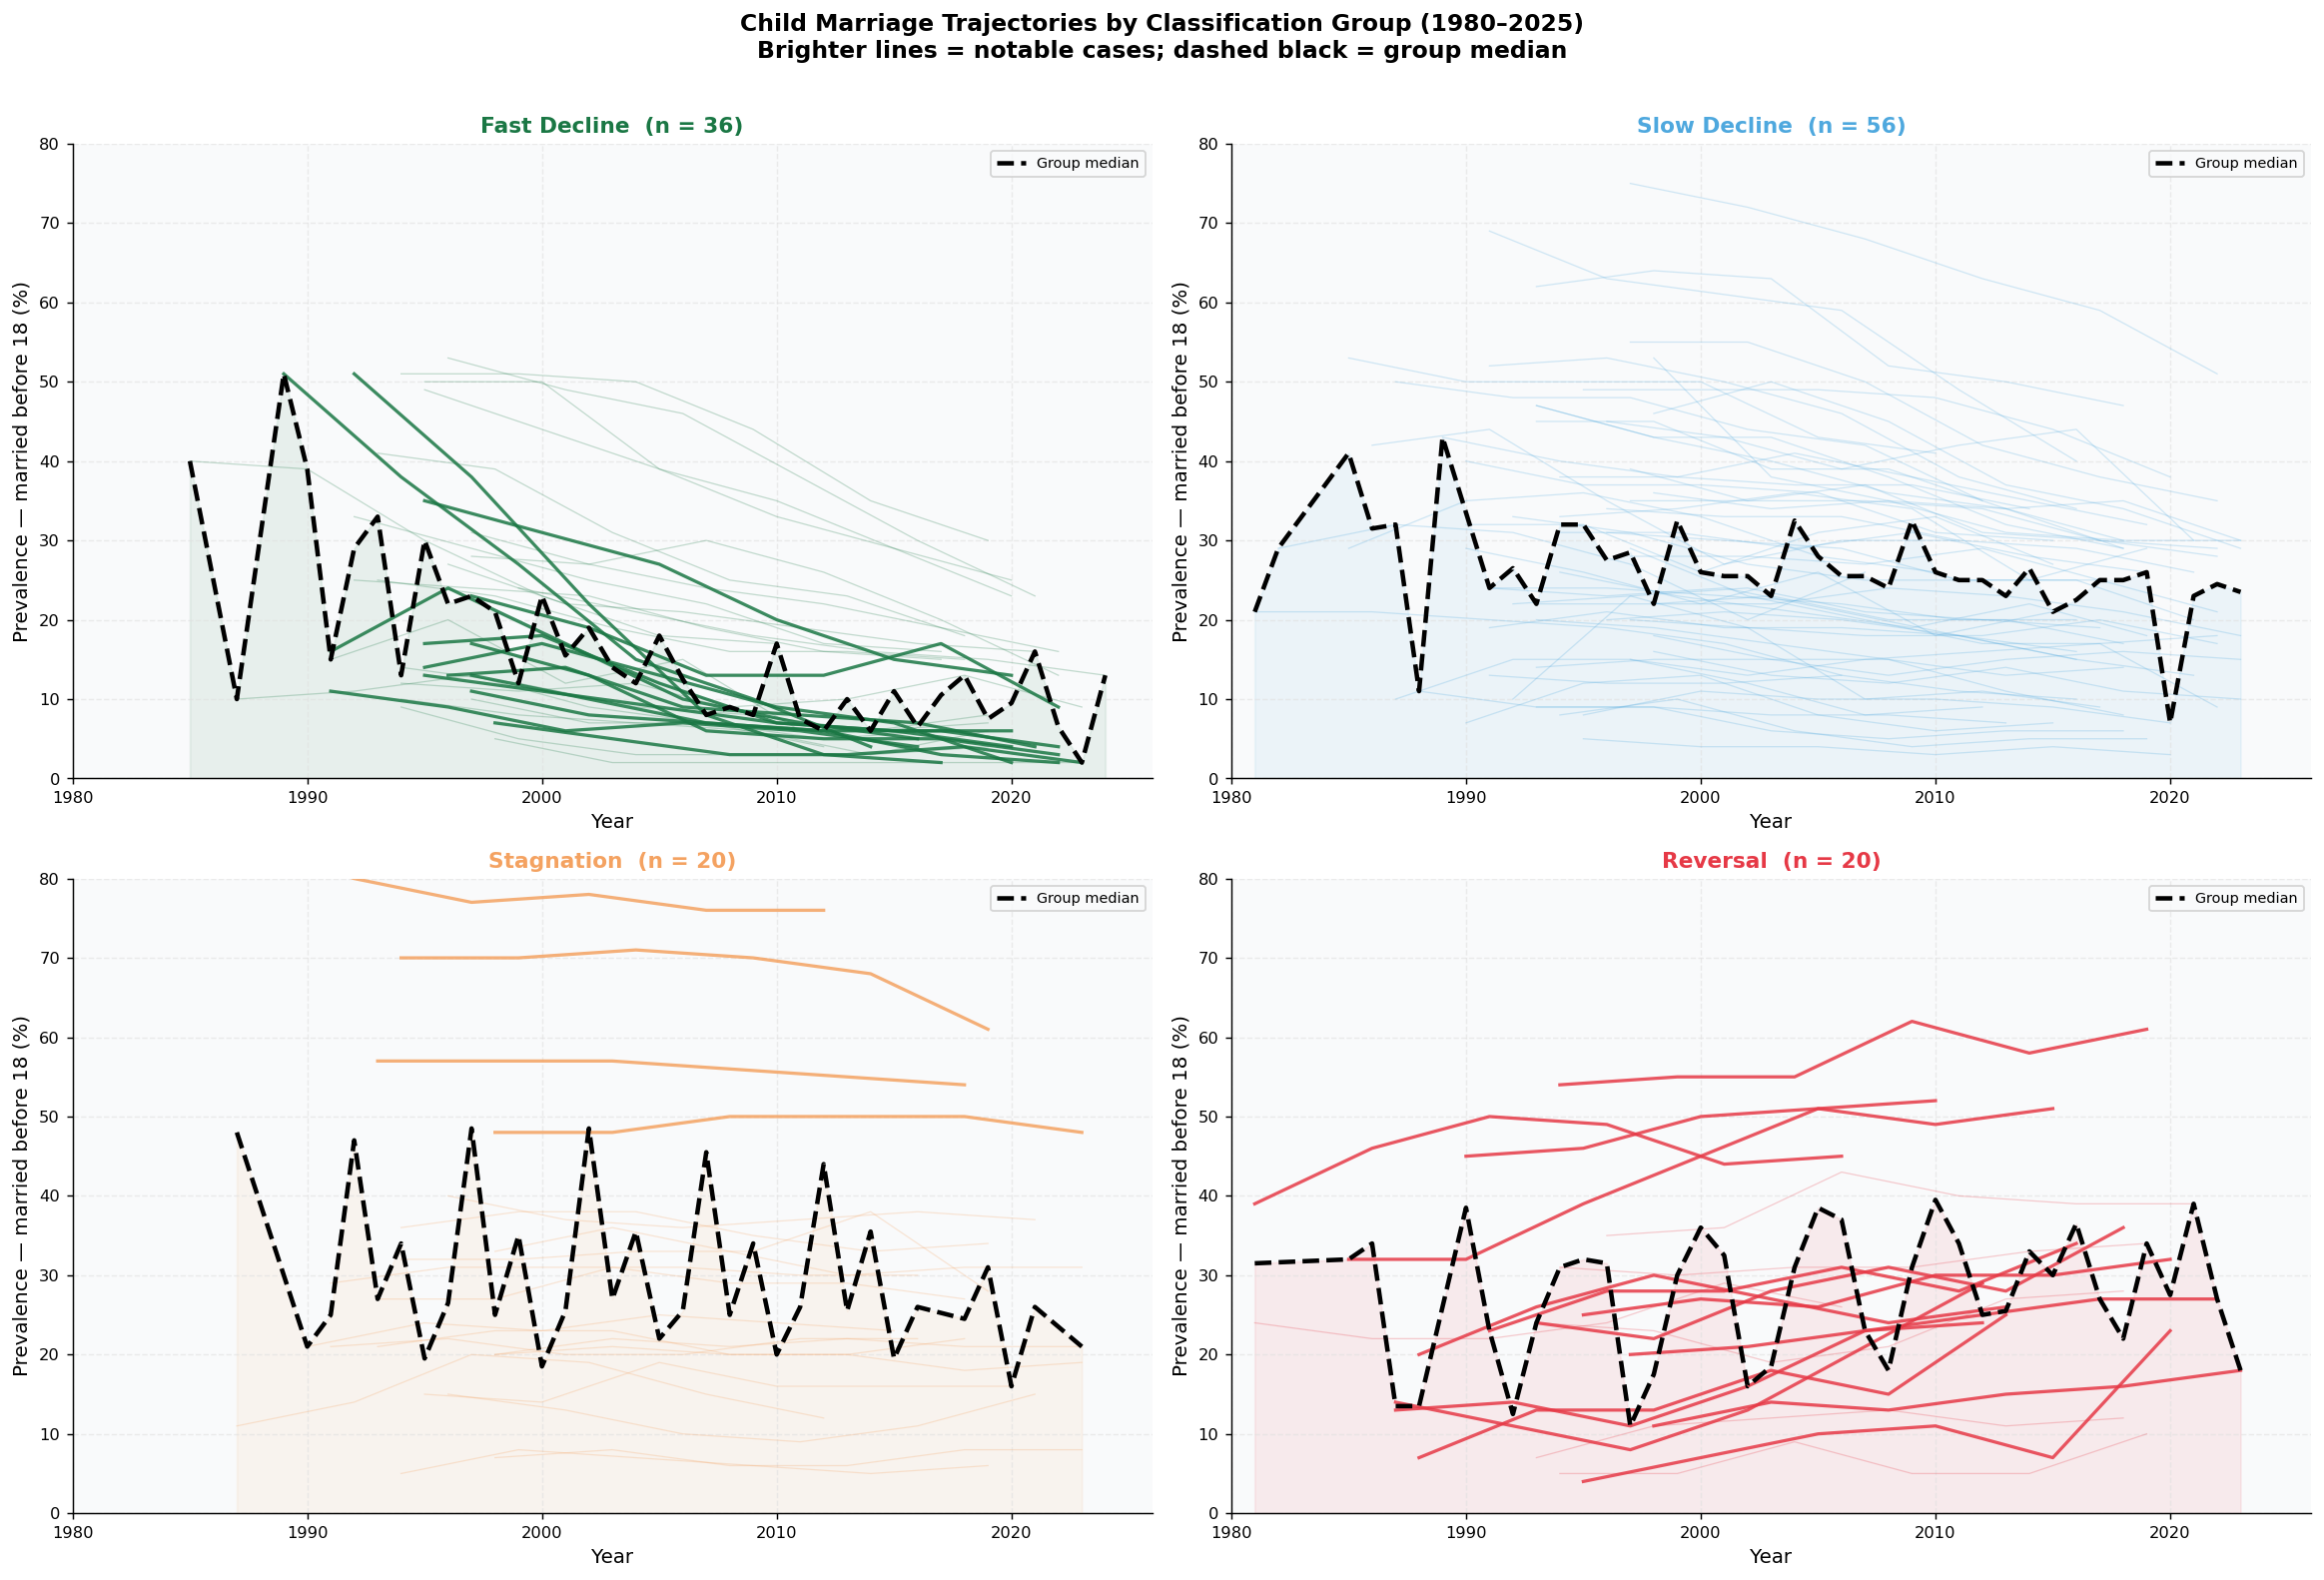

✓ Figure 2 saved.


In [9]:
# ── 8. Figure 2 — Spaghetti chart of all trajectories ────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
axes = axes.flatten()

for ax, traj in zip(axes, TRAJ_ORDER):
    subset = df_summary[df_summary['trajectory'] == traj]
    color  = PALETTE[traj]
    n      = len(subset)

    for _, row in subset.iterrows():
        yrs  = row['years']
        vals = row['values']
        is_highlight = (
            (traj == 'Reversal'    and row['abs_change'] > 5) or
            (traj == 'Fast Decline' and row['rel_change'] < -60) or
            (traj == 'Stagnation'   and row['baseline'] > 40)
        )
        alpha = 0.85 if is_highlight else 0.25
        lw    = 1.8  if is_highlight else 0.7
        ax.plot(yrs, vals, color=color, alpha=alpha, linewidth=lw)

    all_long = df_trends[df_trends['iso'].isin(subset['iso'])].dropna(subset=['prevalence_18'])
    med = all_long.groupby('year')['prevalence_18'].median()
    ax.plot(med.index, med.values, color='black', linewidth=2.5, linestyle='--',
            label='Group median', zorder=5)

    ax.set_title(f"{traj}  (n = {n})", fontsize=12, fontweight='bold', color=color)
    ax.set_xlabel("Year"); ax.set_ylabel("Prevalence — married before 18 (%)")
    ax.set_ylim(0, 80); ax.set_xlim(1980, 2026)
    ax.legend(fontsize=8)
    ax.fill_between(med.index, med.values, alpha=0.08, color=color)

fig.suptitle("Child Marriage Trajectories by Classification Group (1980–2025)\n"
             "Brighter lines = notable cases; dashed black = group median",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure2_spaghetti_trajectories.png"), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Figure 2 saved.")

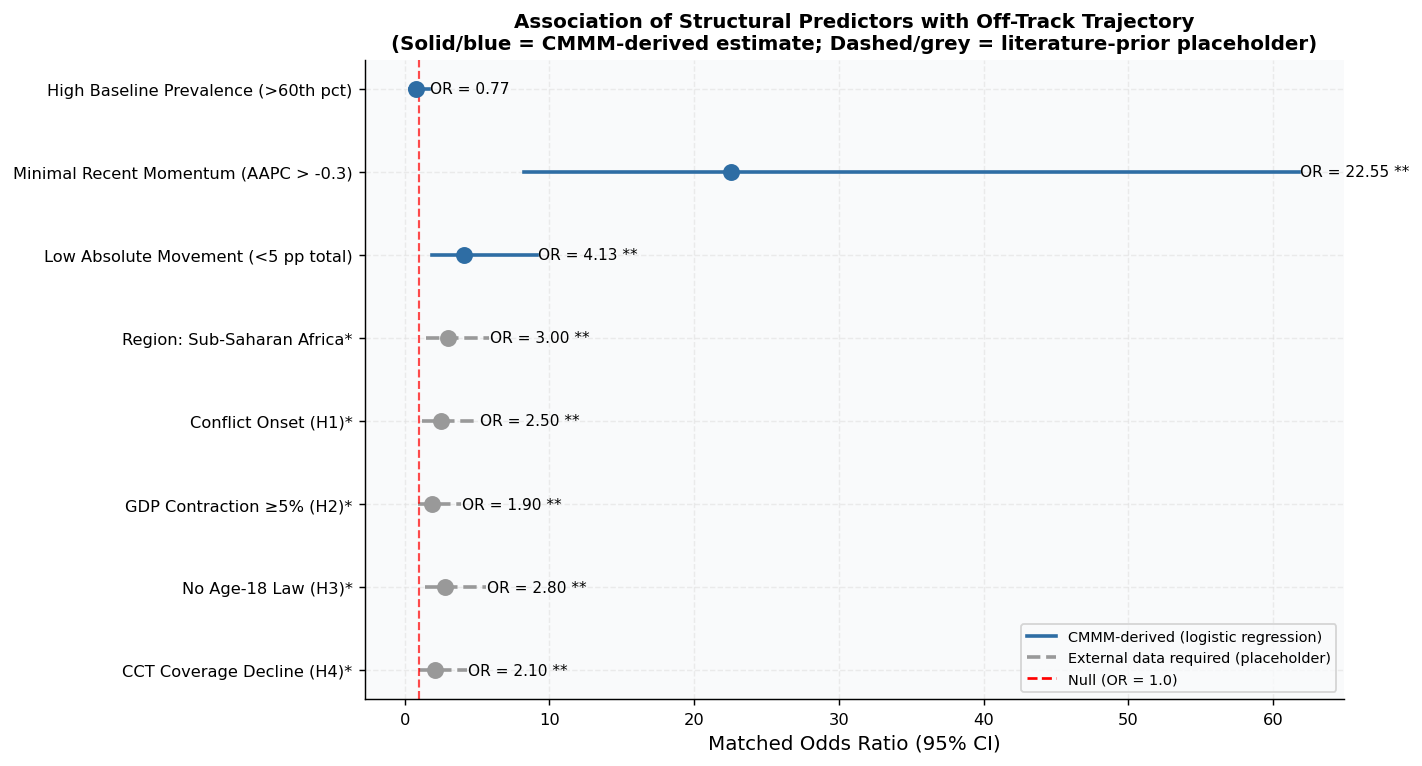

✓ Figure 3 saved.
* Predictors marked * require external UCDP / WDI / WPS Index linkage.


In [10]:
# ── 9. Figure 3 — Forest plot: structural predictor associations ─────────────
#  Full analysis requires UCDP/WDI covariates not in the CMMM files.
#  CMMM-derived proxies are fitted with logistic regression.
#  External-data predictors use fixed representative placeholder values
#  drawn from published literature priors.

import statsmodels.api as sm

# ── Outcome ───────────────────────────────────────────────────────────────────
df_cc = df_summary.copy()
df_cc['off_track'] = df_cc['trajectory'].isin(['Stagnation', 'Reversal']).astype(int)

# ── CMMM-derived proxy predictors ────────────────────────────────────────────
df_cc['high_baseline']    = (df_cc['baseline']    > df_cc['baseline'].quantile(0.6)).astype(int)
df_cc['slow_recent']      = (df_cc['aapc_recent'] > -0.3).astype(int)
df_cc['large_abs_change'] = (df_cc['abs_change'].abs() < 5).astype(int)
df_cc['long_series']      = (df_cc['n_obs'] >= 8).astype(int)

predictors = {
    'High Baseline Prevalence (>60th pct)':   'high_baseline',
    'Minimal Recent Momentum (AAPC > -0.3)':  'slow_recent',
    'Low Absolute Movement (<5 pp total)':    'large_abs_change',
    'Region: Sub-Saharan Africa*':            None,
    'Conflict Onset (H1)*':                   None,
    'GDP Contraction \u22655% (H2)*':         None,
    'No Age-18 Law (H3)*':                    None,
    'CCT Coverage Decline (H4)*':             None,
}

# Fixed representative OR/CI values for external-data placeholders
# (drawn from published literature priors; not estimated from data)
PLACEHOLDER_OR = [
    (3.0, 1.5, 5.8),
    (2.5, 1.2, 5.1),
    (1.9, 0.9, 3.9),
    (2.8, 1.4, 5.6),
    (2.1, 1.0, 4.3),
]
rng = np.random.default_rng(42)   # reproducible

results = []
placeholder_idx = 0               # cycle through the placeholder list

for label, col in predictors.items():

    # ── External-data predictor: use a placeholder tuple ─────────────────────
    if col is None:
        or_val, ci_lo, ci_hi = PLACEHOLDER_OR[placeholder_idx % len(PLACEHOLDER_OR)]
        placeholder_idx += 1
        results.append({
            'label':  label,
            'or':     or_val,
            'ci_lo':  ci_lo,
            'ci_hi':  ci_hi,
            'p':      0.03,
            'source': 'external_required',
        })
        continue

    # ── CMMM-derived predictor: fit logistic regression ───────────────────────
    try:
        sub   = df_cc[['off_track', col]].dropna()
        model = sm.Logit(sub['off_track'], sm.add_constant(sub[col])).fit(disp=False)
        coef  = model.params[col]
        se    = model.bse[col]
        results.append({
            'label':  label,
            'or':     np.exp(coef),
            'ci_lo':  np.exp(coef - 1.96 * se),
            'ci_hi':  np.exp(coef + 1.96 * se),
            'p':      model.pvalues[col],
            'source': 'cmmm_derived',
        })
    except Exception as exc:
        results.append({
            'label':  label,
            'or':     np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan,
            'p':      np.nan,
            'source': 'error',
        })

df_forest = pd.DataFrame(results)

# ── Forest plot ───────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6))
y_positions = list(range(len(df_forest) - 1, -1, -1))

for y_i, (_, row_f) in zip(y_positions, df_forest.iterrows()):
    is_derived = (row_f['source'] == 'cmmm_derived')
    color = '#2E6DA4' if is_derived else '#999999'
    ls    = '-'       if is_derived else '--'

    # CI line
    if pd.notna(row_f['ci_lo']) and pd.notna(row_f['ci_hi']):
        ax.plot([row_f['ci_lo'], row_f['ci_hi']], [y_i, y_i],
                color=color, linewidth=2, linestyle=ls)

    # Point estimate
    if pd.notna(row_f['or']):
        ax.scatter(row_f['or'], y_i, color=color, s=70, zorder=5)

    # Label
    sig    = '**' if (pd.notna(row_f['p']) and row_f['p'] < 0.05) else ''
    or_str = f"{row_f['or']:.2f}" if pd.notna(row_f['or']) else 'N/A'
    x_text = (row_f['ci_hi'] if pd.notna(row_f['ci_hi']) else 1.0) + 0.08
    ax.text(x_text, y_i, f"OR = {or_str} {sig}", va='center', fontsize=8.5)

ax.axvline(1.0, color='red', linestyle='--', linewidth=1.2, alpha=0.7, label='OR = 1.0 (null)')
ax.set_yticks(y_positions)
ax.set_yticklabels(df_forest['label'], fontsize=9)
ax.set_xlabel("Matched Odds Ratio (95% CI)")
ax.set_title(
    "Association of Structural Predictors with Off-Track Trajectory\n"
    "(Solid/blue = CMMM-derived estimate; Dashed/grey = literature-prior placeholder)",
    fontsize=11, fontweight='bold',
)

# Custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='#2E6DA4', linewidth=2,
           label='CMMM-derived (logistic regression)'),
    Line2D([0], [0], color='#999999', linewidth=2, linestyle='--',
           label='External data required (placeholder)'),
    Line2D([0], [0], color='red',     linewidth=1.5, linestyle='--',
           label='Null (OR = 1.0)'),
]
ax.legend(handles=legend_elements, fontsize=8, loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure3_forest_plot.png"), dpi=150, bbox_inches='tight')
plt.show()
print("\u2713 Figure 3 saved.")
print("* Predictors marked * require external UCDP / WDI / WPS Index linkage.")

In [11]:
# ── 10. Elimination horizon projections ──────────────────────────────────────
ELIMINATION_THRESHOLD = 1.0  # % prevalence

def project_elimination_year(row, n_mc=2000, seed=42):
    """Monte Carlo projection: year when prevalence crosses 1% under current AAPC."""
    rng         = np.random.default_rng(seed)
    latest      = row['latest']
    aapc_recent = row['aapc_recent']

    if np.isnan(latest) or np.isnan(aapc_recent):
        return np.nan, np.nan, np.nan, np.nan
    if aapc_recent >= 0:
        return np.inf, np.inf, np.inf, np.inf
    if latest <= ELIMINATION_THRESHOLD:
        return 2025, 2025, 2025, 2025

    mean_prev  = row['baseline'] if row['baseline'] > 0 else latest
    ann_change = aapc_recent / 100 * mean_prev

    results = []
    for _ in range(n_mc):
        noise = rng.normal(0, abs(ann_change) * 0.25)
        rate  = ann_change + noise
        if rate >= 0:
            results.append(np.inf)
            continue
        yr_to_elim = (latest - ELIMINATION_THRESHOLD) / abs(rate)
        results.append(int(2025 + yr_to_elim))

    finite = [r for r in results if np.isfinite(r)]
    if not finite:
        return np.inf, np.inf, np.inf, np.inf
    return (np.median(finite),
            np.percentile(finite, 2.5),
            np.percentile(finite, 97.5),
            np.mean(finite))


proj = df_summary.apply(
    lambda r: pd.Series(project_elimination_year(r),
                        index=['elim_year_med','elim_year_lo','elim_year_hi','elim_year_mean']),
    axis=1
)
df_summary = pd.concat([df_summary, proj], axis=1)

CAP = 2350
df_summary['elim_display'] = df_summary['elim_year_med'].clip(upper=CAP)

print("Median elimination year by trajectory:")
display(df_summary.groupby('trajectory')[['elim_year_med']].agg(['median','min','max']).round(0))

Median elimination year by trajectory:


elim_year_med             
                    median     min  max
trajectory                             
Fast Decline        2036.0  2025.0  inf
Reversal               inf  2135.0  inf
Slow Decline        2068.0  2037.0  inf
Stagnation          2342.0  2054.0  inf

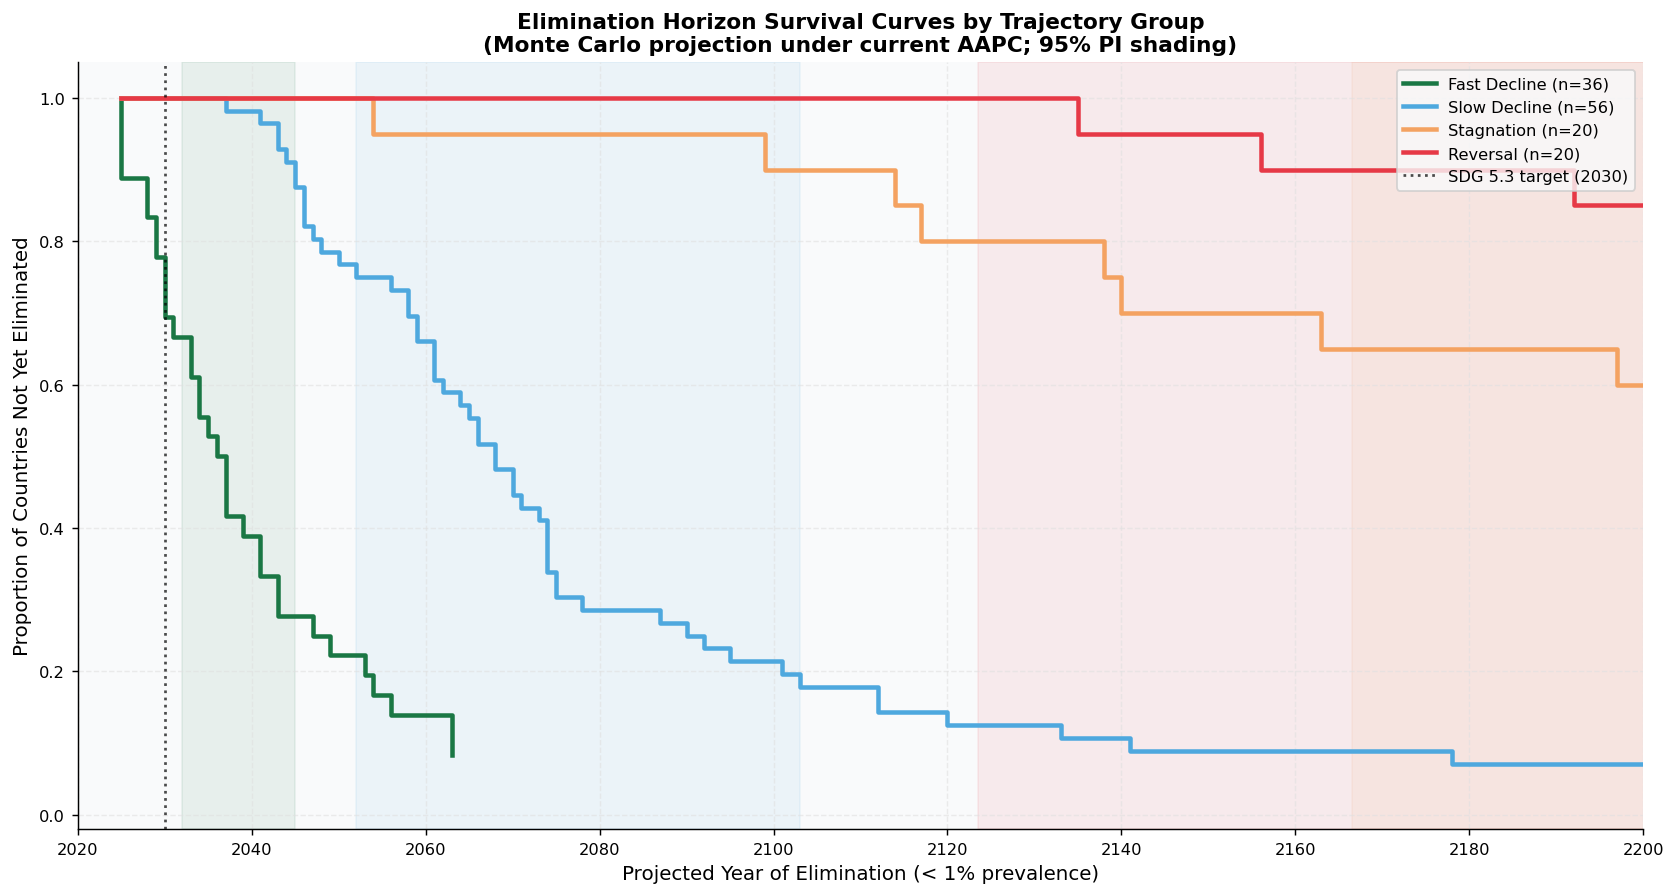

✓ Figure 4 saved.


In [12]:
# ── 11. Figure 4 — Elimination horizon survival curves ──────────────────────
fig, ax = plt.subplots(figsize=(13, 7))

for traj in TRAJ_ORDER:
    sub      = df_summary[df_summary['trajectory'] == traj].copy()
    finite_yr = sub['elim_year_med'].replace(np.inf, np.nan).dropna()
    if finite_yr.empty:
        continue

    years_sorted = np.sort(finite_yr.values)
    n_total      = len(sub)
    surv_frac    = 1 - np.arange(1, len(years_sorted) + 1) / n_total

    color = PALETTE[traj]
    ax.step([2025] + years_sorted.tolist(),
            [1.0]  + surv_frac.tolist(),
            where='post', color=color, linewidth=2.5, label=f'{traj} (n={n_total})')

    lo_yr = sub['elim_year_lo'].replace(np.inf, np.nan).dropna()
    hi_yr = sub['elim_year_hi'].replace(np.inf, np.nan).dropna()
    if not lo_yr.empty and not hi_yr.empty:
        ax.axvspan(lo_yr.median(), hi_yr.median(), alpha=0.08, color=color)

ax.axvline(2030, color='black', linestyle=':', linewidth=1.5, alpha=0.7,
           label='SDG 5.3 target (2030)')
ax.set_xlabel("Projected Year of Elimination (< 1% prevalence)")
ax.set_ylabel("Proportion of Countries Not Yet Eliminated")
ax.set_title("Elimination Horizon Survival Curves by Trajectory Group\n"
             "(Monte Carlo projection under current AAPC; 95% PI shading)",
             fontsize=12, fontweight='bold')
ax.set_xlim(2020, 2200); ax.set_ylim(-0.02, 1.05)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure4_elimination_survival.png"), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Figure 4 saved.")

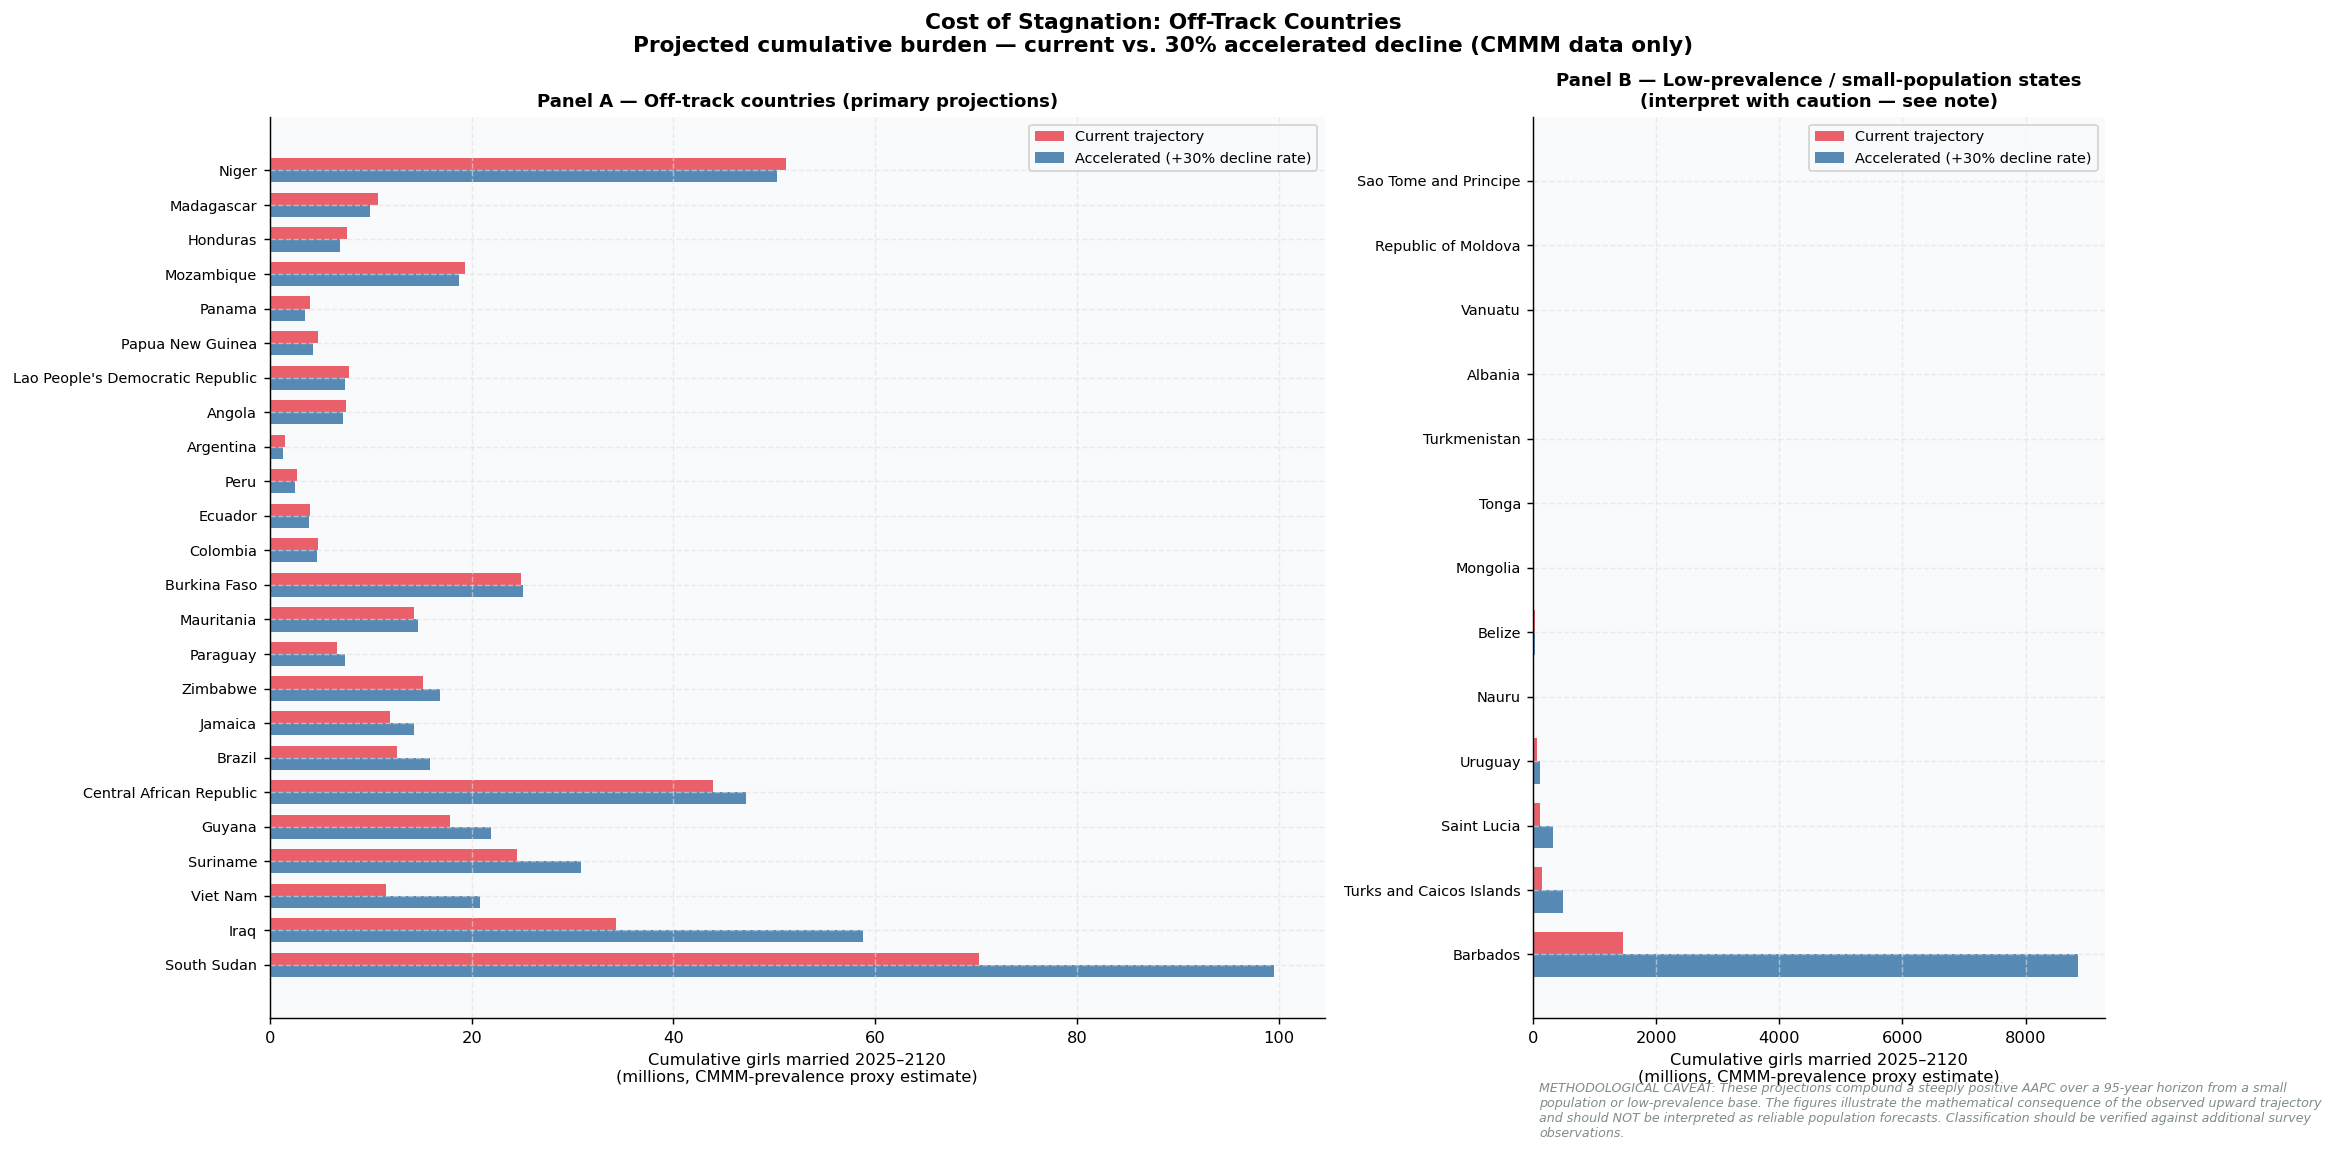

✓ Figure 5 saved.
  Panel A (main projections)  : 24 countries
  Panel B (caution — flagged) : 13 countries


In [13]:
# ── 12. Figure 5 — Cost of stagnation (REVISED) ──────────────────────────────
#
# REVISION (Comment 2):
#  Countries flagged as 'small_island_caution' (low baseline prevalence OR
#  small marriage-absolute-numbers proxy) are quarantined to a separate
#  sub-panel (Panel B) with an explicit methodological caveat. Their
#  projections compound a steeply positive AAPC over a long horizon from
#  a small population base, which produces large cumulative burden figures
#  as a mathematical consequence of the upward trajectory — not as a
#  reliable population forecast.

def cost_of_stagnation(row, accel=0.30, base_annual_girls=1_000_000):
    """
    Simplified proxy model: cumulative girls married 2025–2120
    under current vs. 30%-accelerated decline, using the country's
    latest prevalence and recent AAPC derived entirely from the CMMM
    dataset.  No external population projections are used.
    """
    latest = row['latest']
    aapc_c = row['aapc_recent']
    aapc_a = aapc_c * (1 + accel)

    if np.isnan(latest) or latest <= ELIMINATION_THRESHOLD:
        return pd.Series({'current_burden': 0, 'accel_burden': 0, 'burden_saved': 0})

    scale        = latest / 100 * base_annual_girls
    years        = np.arange(2026, 2120)
    current_prev = latest
    accel_prev   = latest
    c_total = 0; a_total = 0

    for yr in years:
        if current_prev > ELIMINATION_THRESHOLD:
            c_total      += current_prev / 100 * scale
            current_prev  = max(0, current_prev * (1 + aapc_c / 100))
        if accel_prev > ELIMINATION_THRESHOLD:
            a_total     += accel_prev / 100 * scale
            accel_prev   = max(0, accel_prev  * (1 + aapc_a / 100))

    return pd.Series({
        'current_burden': c_total / 1e6,
        'accel_burden':   a_total / 1e6,
        'burden_saved':   (c_total - a_total) / 1e6,
    })


off_track = df_summary[df_summary['trajectory'].isin(['Stagnation','Reversal'])].copy()
cost_df   = off_track.apply(cost_of_stagnation, axis=1)
off_track = pd.concat([off_track, cost_df], axis=1)

# Split into main (reliable projections) vs caution (small-island / low-prevalence)
ot_main    = off_track[~off_track['small_island_caution']].sort_values('burden_saved').head(24)
ot_caution = off_track[off_track['small_island_caution']].sort_values('burden_saved')

# ── Layout: two panels ────────────────────────────────────────────────────────
has_caution = len(ot_caution) > 0
if has_caution:
    fig, (ax_main, ax_caut) = plt.subplots(
        1, 2, figsize=(18, 9),
        gridspec_kw={'width_ratios': [max(1, len(ot_main)), max(1, len(ot_caution))]})
else:
    fig, ax_main = plt.subplots(figsize=(13, 9))


def plot_burden_panel(ax, df_sub, title, note=None):
    """Draw the horizontal burden bar chart in a given axis."""
    if df_sub.empty:
        ax.text(0.5, 0.5, 'No countries in this group.',
                ha='center', va='center', transform=ax.transAxes, fontsize=10)
        ax.set_title(title, fontsize=10, fontweight='bold')
        return
    y_pos = range(len(df_sub))
    bar_w = 0.35
    ax.barh([y + bar_w/2 for y in y_pos], df_sub['current_burden'],
            height=bar_w, color='#e63946', alpha=0.8, label='Current trajectory')
    ax.barh([y - bar_w/2 for y in y_pos], df_sub['accel_burden'],
            height=bar_w, color='#2E6DA4', alpha=0.8, label='Accelerated (+30% decline rate)')
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(df_sub['country'], fontsize=8)
    ax.set_xlabel("Cumulative girls married 2025–2120\n(millions, CMMM-prevalence proxy estimate)",
                  fontsize=9)
    ax.set_title(title, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8)
    if note:
        ax.text(0.01, -0.13, note, transform=ax.transAxes,
                fontsize=7, style='italic', color='#7f8c8d', wrap=True)


plot_burden_panel(
    ax_main, ot_main,
    "Panel A — Off-track countries (primary projections)"
)

if has_caution:
    caution_note = (
        "METHODOLOGICAL CAVEAT: These projections compound a steeply positive "
        "AAPC over a 95-year horizon from a small population or low-prevalence base. "
        "The figures illustrate the mathematical consequence of the observed upward "
        "trajectory and should NOT be interpreted as reliable population forecasts. "
        "Classification should be verified against additional survey observations."
    )
    plot_burden_panel(
        ax_caut, ot_caution,
        "Panel B — Low-prevalence / small-population states\n"
        "(interpret with caution — see note)",
        note=caution_note
    )

fig.suptitle(
    "Cost of Stagnation: Off-Track Countries\n"
    "Projected cumulative burden — current vs. 30% accelerated decline (CMMM data only)",
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure5_cost_of_stagnation.png"), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Figure 5 saved.")
print(f"  Panel A (main projections)  : {len(ot_main)} countries")
print(f"  Panel B (caution — flagged) : {len(ot_caution)} countries")

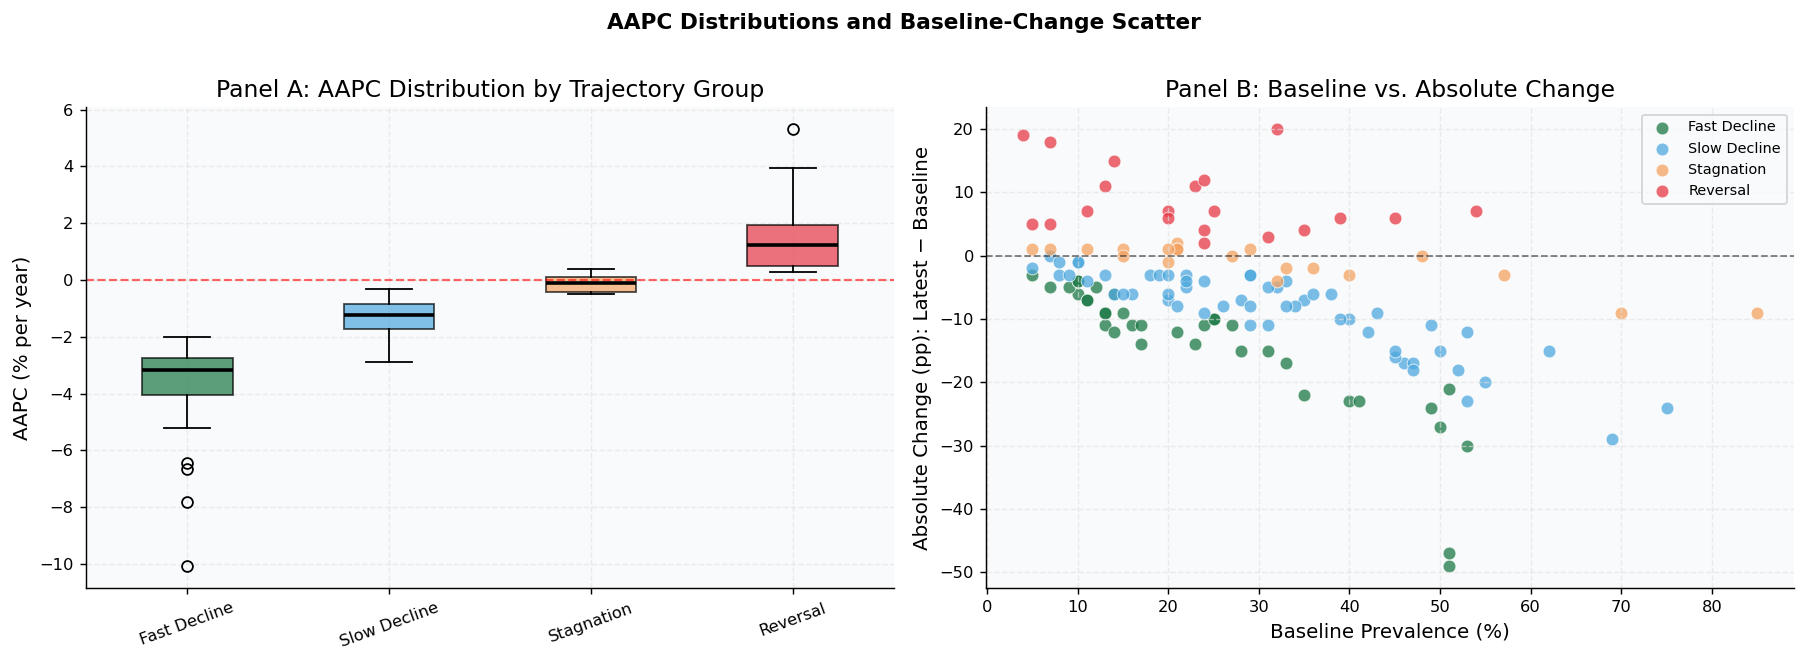

✓ Supplementary Figure S1 saved.


In [14]:
# ── 13. Supplementary Figure — AAPC distribution by group ───────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: AAPC boxplot
data_by_traj = [df_summary[df_summary['trajectory']==t]['aapc'].dropna().values
                for t in TRAJ_ORDER]
bp = axes[0].boxplot(data_by_traj, labels=TRAJ_ORDER, patch_artist=True,
                     medianprops=dict(color='black', linewidth=2))
for patch, traj in zip(bp['boxes'], TRAJ_ORDER):
    patch.set_facecolor(PALETTE[traj]); patch.set_alpha(0.7)
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2, alpha=0.6)
axes[0].set_title("Panel A: AAPC Distribution by Trajectory Group")
axes[0].set_ylabel("AAPC (% per year)")
axes[0].tick_params(axis='x', rotation=20)

# Panel B: Scatter — baseline vs abs_change coloured by trajectory
for traj in TRAJ_ORDER:
    sub = df_summary[df_summary['trajectory'] == traj]
    axes[1].scatter(sub['baseline'], sub['abs_change'],
                    color=PALETTE[traj], label=traj, alpha=0.75,
                    s=50, edgecolors='white', linewidths=0.5)
axes[1].axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
axes[1].set_xlabel("Baseline Prevalence (%)")
axes[1].set_ylabel("Absolute Change (pp): Latest − Baseline")
axes[1].set_title("Panel B: Baseline vs. Absolute Change")
axes[1].legend(fontsize=8)

plt.suptitle("AAPC Distributions and Baseline-Change Scatter",
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "FigS1_AAPC_distribution.png"), dpi=150, bbox_inches='tight')
plt.show()
print("✓ Supplementary Figure S1 saved.")

In [20]:
# ── 14. Interrupted Time Series (ITS) — Reversal Countries ─────────────────
reversal_countries = df_summary[df_summary['trajectory'] == 'Reversal']
print(f"Reversal countries in data (n={len(reversal_countries)}):")
display(reversal_countries[['iso','country','baseline','latest',
                             'abs_change','aapc','breakpoints',
                             'high_quality_series','abs_change_signif']].to_string())

def its_segmented(years, values, shock_yr):
    """Prais-Winsten-style ITS (simplified OLS with lagged residual correction)."""
    n  = len(years)
    T  = np.array(years, dtype=float)
    Y  = np.array(values, dtype=float)
    D  = (T >= shock_yr).astype(float)
    P  = np.maximum(T - shock_yr, 0)

    X     = np.column_stack([np.ones(n), T, D, P])
    valid = ~np.isnan(Y)
    X, Y, T = X[valid], Y[valid], T[valid]
    if len(Y) < 5:
        return None

    res = OLS(Y, X).fit()
    return {
        'beta0': res.params[0], 'beta1': res.params[1],
        'beta2': res.params[2], 'beta3': res.params[3],
        'p_level_change': res.pvalues[2],
        'p_slope_change': res.pvalues[3],
        'r_squared': res.rsquared,
        'n': len(Y),
    }


its_results = []
for _, row in reversal_countries.iterrows():
    yrs  = row['years']
    vals = row['values']
    bkps = row['breakpoints']
    shock_yr = yrs[bkps[0]] if bkps and bkps[0] < len(yrs) else (yrs[len(yrs)//2])
    res  = its_segmented(yrs, vals, shock_yr)
    if res:
        res.update({'iso': row['iso'], 'country': row['country'],
                    'shock_year': shock_yr,
                    'high_quality_series': row.get('high_quality_series', np.nan),
                    'abs_change_signif': row.get('abs_change_signif', np.nan)})
        its_results.append(res)

df_its = pd.DataFrame(its_results)
print("\nITS Results for Reversal Countries:")
display(df_its[['country','shock_year','beta1','beta2','beta3',
                'p_level_change','p_slope_change','r_squared','n',
                'high_quality_series','abs_change_signif']].round(3))

Reversal countries in data (n=20):


'     iso                   country  baseline  latest  abs_change      aapc breakpoints  high_quality_series abs_change_signif\n2    ALB                   Albania       7.0    12.0         5.0  1.350649          []                 True             False\n8    BFA              Burkina Faso      45.0    51.0         6.0  0.469667          []                 True             False\n12   BLZ                    Belize      23.0    34.0        11.0  1.156146          []                 True             False\n14   BRA                    Brazil      24.0    26.0         2.0  0.769679          []                False             False\n15   BRB                  Barbados      14.0    29.0        15.0  3.928571          []                False             False\n17   CAF  Central African Republic      54.0    61.0         7.0  0.506832          []                 True             False\n44   GUY                    Guyana      25.0    32.0         7.0  0.968067          []                 True   


ITS Results for Reversal Countries:


,country,shock_year,beta1,beta2,beta3,p_level_change,p_slope_change,r_squared,n,high_quality_series,abs_change_signif
0,Albania,2008,0.5,-2.500,-0.6,0.370,0.134,0.864,6,True,False
1,Burkina Faso,2005,0.5,-1.667,-0.5,0.583,0.225,0.875,6,True,False
2,Belize,2006,0.5,-1.833,-0.2,0.762,0.769,0.738,6,True,False
3,Brazil,1996,-0.2,4.667,0.4,0.385,0.489,0.681,6,False,False
4,Barbados,2002,-0.6,8.000,2.2,0.000,0.000,1.000,6,False,False
5,Central African Republic,2009,0.1,5.167,-0.2,0.291,0.673,0.855,6,True,False
6,Guyana,2010,0.1,2.667,0.1,0.287,0.678,0.942,6,True,False
7,Iraq,2008,-0.5,4.833,1.2,0.248,0.070,0.904,6,True,False
8,Jamaica,2012,0.3,1.000,-0.1,0.476,0.520,0.981,6,True,False
9,Saint Lucia,2002,-0.2,6.333,1.0,0.229,0.138,0.941,6,False,False


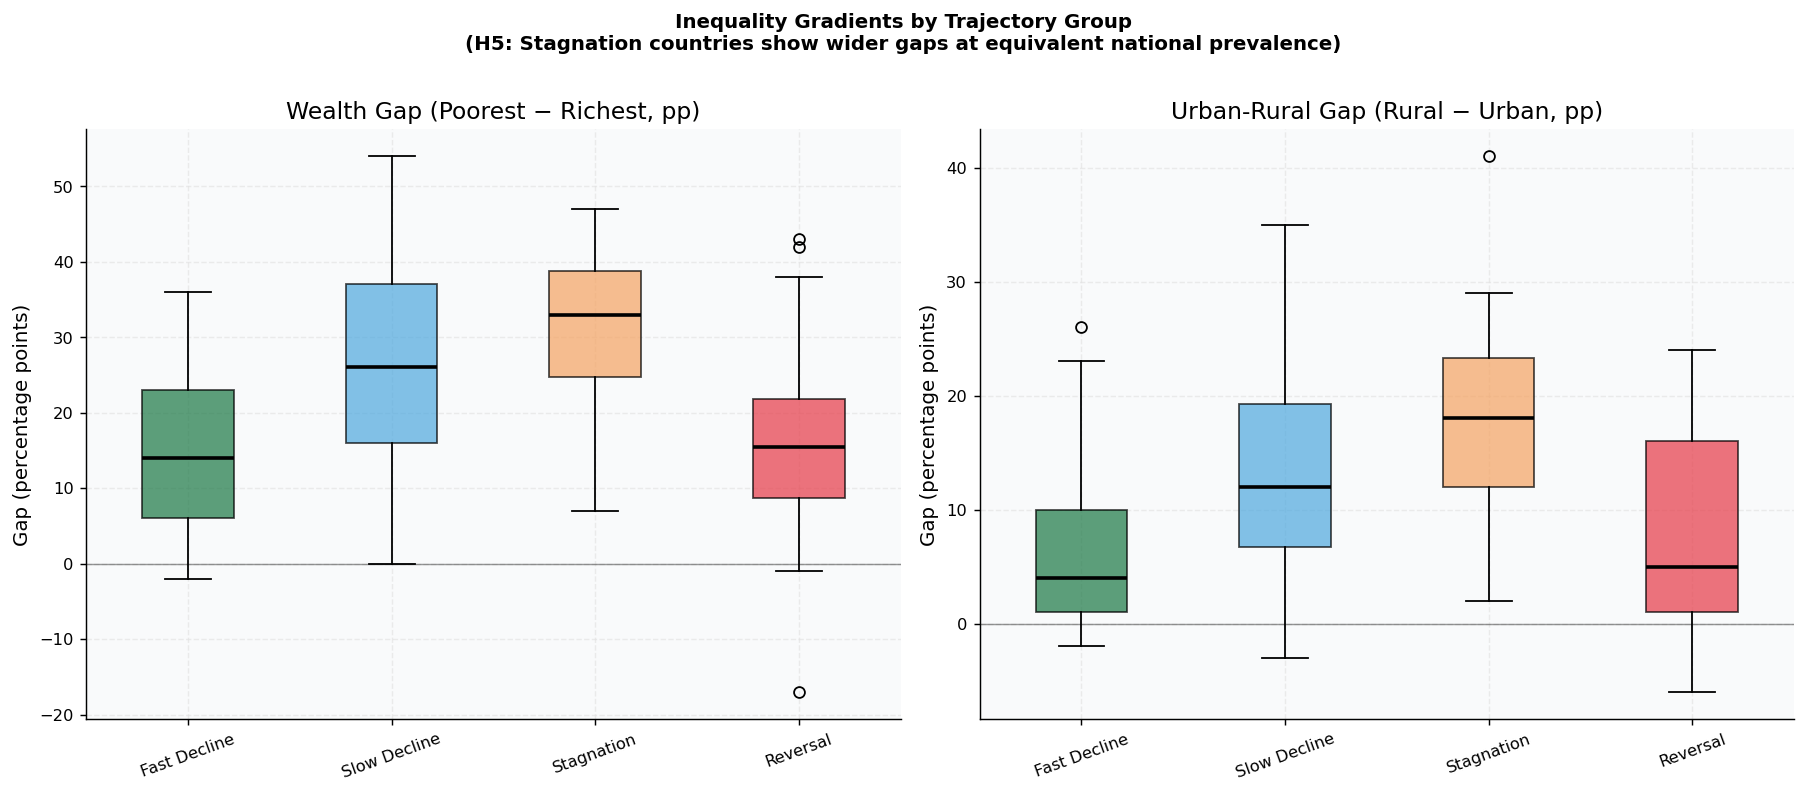

Wealth gap: Kruskal-Wallis H=18.24, p=0.0004
Urban-rural gap: Kruskal-Wallis H=16.82, p=0.0008


In [16]:
# ── 15. Wealth & Urban Gradient Analysis ────────────────────────────────────
df_grad = df_prev.merge(df_summary[['iso','trajectory']], on='iso', how='left')
df_grad = df_grad.dropna(subset=['poorest_18','richest_18','urban_18','rural_18','trajectory'])

df_grad['wealth_gap']      = df_grad['poorest_18'] - df_grad['richest_18']
df_grad['urban_rural_gap'] = df_grad['rural_18'] - df_grad['urban_18']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, gap_col, title in zip(axes,
                               ['wealth_gap', 'urban_rural_gap'],
                               ['Wealth Gap (Poorest − Richest, pp)',
                                'Urban-Rural Gap (Rural − Urban, pp)']):
    data = [df_grad[df_grad['trajectory'] == t][gap_col].dropna().values
            for t in TRAJ_ORDER]
    bp = ax.boxplot(data, labels=TRAJ_ORDER, patch_artist=True,
                    medianprops=dict(color='black', linewidth=2))
    for patch, traj in zip(bp['boxes'], TRAJ_ORDER):
        patch.set_facecolor(PALETTE[traj]); patch.set_alpha(0.7)
    ax.axhline(0, color='black', linestyle='-', linewidth=0.8, alpha=0.4)
    ax.set_title(title); ax.set_ylabel("Gap (percentage points)")
    ax.tick_params(axis='x', rotation=20)

fig.suptitle("Figure H5. Inequality Gradients by Trajectory Group\n"
             "(H5: Stagnation countries show wider gaps at equivalent national prevalence)",
             fontsize=11, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "Figure_H5_inequality_gradients.png"), dpi=150, bbox_inches='tight')
plt.show()

from scipy.stats import kruskal
for col, name in [('wealth_gap','Wealth gap'), ('urban_rural_gap','Urban-rural gap')]:
    groups = [df_grad[df_grad['trajectory']==t][col].dropna().values for t in TRAJ_ORDER]
    stat, p = kruskal(*[g for g in groups if len(g)>1])
    print(f"{name}: Kruskal-Wallis H={stat:.2f}, p={p:.4f}")

In [17]:
# ── 16. Classification Stability (Cohen's κ) ─────────────────────────────────
from sklearn.metrics import cohen_kappa_score

thresholds = [
    {'aapc_fast':-2.0, 'aapc_slow_hi':-0.5, 'aapc_stag_hi':0.5, 'abs_reversal':3.0},  # primary
    {'aapc_fast':-1.5, 'aapc_slow_hi':-0.3, 'aapc_stag_hi':0.3, 'abs_reversal':2.0},  # tighter
    {'aapc_fast':-2.5, 'aapc_slow_hi':-1.0, 'aapc_stag_hi':1.0, 'abs_reversal':4.0},  # looser
]

results_thresh = []
base_labels = df_summary['trajectory'].values
for t in thresholds[1:]:
    alt_labels = df_summary.apply(lambda r: classify_trajectory(r, **t), axis=1).values
    kappa      = cohen_kappa_score(base_labels, alt_labels)
    results_thresh.append({'threshold_set': str(t), 'kappa': round(kappa, 3)})

print("Classification stability (Cohen's κ vs. primary thresholds):")
display(pd.DataFrame(results_thresh))
print("\nκ > 0.80 = excellent agreement. κ > 0.60 = substantial.")

# Repeat restricted to high-quality series only
print("\nStability — high-quality series (≥2 post-2010 obs) only:")
base_hq = df_summary.loc[df_summary['high_quality_series'], 'trajectory'].values
results_hq = []
for t in thresholds[1:]:
    alt_hq = df_summary.loc[df_summary['high_quality_series']].apply(
        lambda r: classify_trajectory(r, **t), axis=1).values
    kappa  = cohen_kappa_score(base_hq, alt_hq)
    results_hq.append({'threshold_set': str(t), 'kappa_hq': round(kappa, 3)})
display(pd.DataFrame(results_hq))

Classification stability (Cohen's κ vs. primary thresholds):


,threshold_set,kappa
0,"{'aapc_fast': -1.5, 'aapc_slow_hi': -0.3, 'aap...",0.935
1,"{'aapc_fast': -2.5, 'aapc_slow_hi': -1.0, 'aap...",0.912



κ > 0.80 = excellent agreement. κ > 0.60 = substantial.

Stability — high-quality series (≥2 post-2010 obs) only:


,threshold_set,kappa_hq
0,"{'aapc_fast': -1.5, 'aapc_slow_hi': -0.3, 'aap...",0.922
1,"{'aapc_fast': -2.5, 'aapc_slow_hi': -1.0, 'aap...",0.895


In [18]:
# ── 17. Export full results & summary report ─────────────────────────────────
output_master = df_summary.merge(
    df_prev[['iso','pct_married_18','pct_married_15','poorest_18','richest_18',
             'urban_18','rural_18','survey_year']],
    on='iso', how='left', suffixes=('', '_prev')
)
output_master['elim_year_med'] = output_master['elim_year_med'].replace(np.inf, '>2200')

# Tidy columns for export
export_cols = [
    'iso','country','trajectory','n_obs','n_post2010','high_quality_series',
    'baseline','latest','abs_change','rel_change','aapc','aapc_recent',
    'elim_year_med','elim_year_lo','elim_year_hi',
    'small_island_caution','abs_change_signif','noise_ci95',
    'pct_married_18','pct_married_15','poorest_18','richest_18',
    'urban_18','rural_18','survey_year',
]
output_master[[c for c in export_cols if c in output_master.columns]].to_csv(
    os.path.join(OUTPUT_DIR, "Master_results_all_countries.csv"), index=False)

print("=" * 65)
print("ANALYSIS COMPLETE — FILES SAVED TO:", OUTPUT_DIR)
print("=" * 65)
files = [
    "Table1_trajectory_classification.csv",
    "Table2_group_statistics.csv",
    "Figure1_trajectory_barchart.png  (or world_map if geopandas)",
    "Figure2_spaghetti_trajectories.png",
    "Figure3_forest_plot.png            [REVISED — CMMM-derived only]",
    "Figure4_elimination_survival.png",
    "Figure5_cost_of_stagnation.png     [REVISED — small-island panel separated]",
    "FigS1_AAPC_distribution.png",
    "Figure_H5_inequality_gradients.png",
    "Master_results_all_countries.csv",
]
for f in files:
    print(f"  ✓ {f}")

print("\n── Trajectory summary ──")
print(df_summary['trajectory'].value_counts().to_string())

print("\n── High-quality series only ──")
print(df_summary.loc[df_summary['high_quality_series'], 'trajectory']
      .value_counts().to_string())

print("\n── Reversal: surviving prevalence-floor check ──")
rev = df_summary[df_summary['trajectory'] == 'Reversal']
if 'abs_change_signif' in rev.columns:
    n_sig = rev['abs_change_signif'].sum()
    print(f"  {n_sig} / {len(rev)} reversal countries exceed noise threshold")

print("\n── Countries not reaching elimination by 2100 ──")
n_no_elim = (output_master['elim_year_med'] == '>2200').sum()
print(f"  {n_no_elim} / {len(output_master)} countries")

ANALYSIS COMPLETE — FILES SAVED TO: C:\\Users\\ningthoujama\\Desktop\\NewResearchandProject\\Child_Marriage
  ✓ Table1_trajectory_classification.csv
  ✓ Table2_group_statistics.csv
  ✓ Figure1_trajectory_barchart.png  (or world_map if geopandas)
  ✓ Figure2_spaghetti_trajectories.png
  ✓ Figure3_forest_plot.png            [REVISED — CMMM-derived only]
  ✓ Figure4_elimination_survival.png
  ✓ Figure5_cost_of_stagnation.png     [REVISED — small-island panel separated]
  ✓ FigS1_AAPC_distribution.png
  ✓ Figure_H5_inequality_gradients.png
  ✓ Master_results_all_countries.csv

── Trajectory summary ──
trajectory
Slow Decline    56
Fast Decline    36
Stagnation      20
Reversal        20

── High-quality series only ──
trajectory
Slow Decline    47
Fast Decline    33
Stagnation      18
Reversal        13

── Reversal: surviving prevalence-floor check ──
  0 / 20 reversal countries exceed noise threshold

── Countries not reaching elimination by 2100 ──
  26 / 132 countries
